In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

In [3]:
# Locate the project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Construct dataset path
dataset_path = project_dir / "data" / "raw" / "dataset.tsv"

# Load the TSV dataset
df = pd.read_csv(dataset_path, sep="\t")

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

display(df.head())

Dataset loaded successfully.
Dataset shape: (2401, 24)


,project,pr_number,id,key,url,bodyText,RQ1 - Scope,RQ1 - Understandability?,selected-sample,RQ2 - Understandability smells,RQ2 - Where,RQ3 - Acceptability,RQ4 - Improvement,RQ5 - Patch Merged,RQ5 - Patch reverted in the pull request,RQ5 - Patch in the last version of the file,RQ5 - Patch reverted in the codebase history,RQ6 - Spotbugs,RQ6 - PMD,RQ6 - SonarQube,RQ6 - Checkstyle,RQ6 - Covered,Implicit or Explicit?,Why is this related to understandability?
0,akvo/akvo-flow,3658,MDI0OlB1bGxSZXF1ZXN0UmV2aWV3Q29tbWVudDUwNzY4ODM4OA==,3,https://codeupcrc.github.io/?key=3,"If we follow the current behaviour of the app, it will send requests to the backend until the returned results == 0....",Code,No,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,akvo/akvo-flow,3701,MDI0OlB1bGxSZXF1ZXN0UmV2aWV3Q29tbWVudDUzNTE0MTIzMQ==,1,https://codeupcrc.github.io/?key=1,this complex one can be done with new ArrayList(sourceToCopiedGroupMap.values()) ? not sure the value of stream to j...,Code,No,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,akvo/akvo-flow,3532,MDI0OlB1bGxSZXF1ZXN0UmV2aWV3Q29tbWVudDQxMjE1ODU2OA==,4,https://codeupcrc.github.io/?key=4,We can change this to Collections.singletonList(0L);,Code,Yes,True,"Complex, long, or inadequate logic",Method,Accepted,Replace an expression by an alternative expression,Yes,NaN,Yes,NaN,NONE,NONE,NONE,NONE,False,Implicit,The reviewer suggests an alternative expression that makes the code more concise. It is not related to functionality...
3,akvo/akvo-flow,3673,MDI0OlB1bGxSZXF1ZXN0UmV2aWV3Q29tbWVudDUyNzk0NjY4Mw==,2,https://codeupcrc.github.io/?key=2,Use ds.get() if we know the id of the entity we want,Code,Discard,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,akvo/akvo-flow,3474,MDI0OlB1bGxSZXF1ZXN0UmV2aWV3Q29tbWVudDM5MzgzMjg2NA==,5,https://codeupcrc.github.io/?key=5,Why is this important for this test?,Code,No,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Dataset dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

print("\nDataset information:")
df.info()

Dataset dimensions:
Rows: 2401
Columns: 24

Column names:
1. project
2. pr_number
3. id
4. key
5. url
6. bodyText
7. RQ1 - Scope
8. RQ1 - Understandability?
9. selected-sample
10. RQ2 - Understandability smells
11. RQ2 - Where
12. RQ3 - Acceptability
13. RQ4 - Improvement
14. RQ5 - Patch Merged
15. RQ5 - Patch reverted in the pull request
16. RQ5 - Patch in the last version of the file
17. RQ5 - Patch reverted in the codebase history
18. RQ6 - Spotbugs
19. RQ6 - PMD
20. RQ6 - SonarQube
21. RQ6 - Checkstyle
22. RQ6 - Covered
23. Implicit or Explicit?
24. Why is this related to understandability?

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2401 entries, 0 to 2400
Data columns (total 24 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   project                                       2401 non-null   object
 1   pr_number                                 

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)})

display(missing_values.sort_values(by="Missing Count",ascending=False))

,Missing Count,Missing Percentage
RQ5 - Patch reverted in the pull request,2392,99.63
RQ5 - Patch reverted in the codebase history,2347,97.75
RQ5 - Patch in the last version of the file,2087,86.92
RQ6 - Spotbugs,2079,86.59
RQ5 - Patch Merged,2078,86.55
RQ4 - Improvement,2078,86.55
RQ6 - PMD,2078,86.55
RQ6 - SonarQube,2078,86.55
RQ6 - Checkstyle,2078,86.55
RQ6 - Covered,2078,86.55


In [ ]:
if "bodyText" in df.columns:

    print("Number of missing review comments:")
    print(df["bodyText"].isna().sum())

    print("\nNumber of empty or whitespace-only comments:")
    empty_comments = (df["bodyText"].fillna("").astype(str).str.strip().eq("").sum())
    print(empty_comments)

    print("\nSample review comments:")
    display(df[["bodyText"]].dropna().sample(n=min(10, df["bodyText"].notna().sum()),random_state=42))

else:
    print("The bodyText column was not found.")

Number of missing review comments:
0

Number of empty or whitespace-only comments:
0

Sample review comments:


,bodyText
685,"Please describe some use case for FLAG_ACTIVITY_REORDER_TO_FRONT, the application is working fine without this."
111,"parseObject is hard to understand ,suggest add parseMap method ,refer to the following code TypeReference<HashMap<St..."
1512,"If you try to inject a PluginContainer for some other plugin but that plugin doesn't exist, Guice will refuse to ini..."
1651,Ditto as above.
741,Nit: Some of these can be split into separate test case with a bit of effort and extra RPCs (I'll leave it to you to...
2039,Why did you change this to non blocking queue? What about thread safety?
237,Isn't msgs operated from different threads ? Noticed only now :(
952,Why is this second arg an array?
1532,why not Atomic Long instance.toString()?
450,Can we put a javax validation on this property? Add the null check at startup rather than on each resource call?


In [ ]:
print("Exact duplicate rows:")
print(df.duplicated().sum())

if "bodyText" in df.columns:

    print("\nDuplicate non-null comment texts:")
    print(df.loc[df["bodyText"].notna(), "bodyText"].duplicated().sum())

Exact duplicate rows:
0

Duplicate non-null comment texts:
29


,comment_length_chars,comment_length_words
count,2401.000000,2401.000000
mean,143.409829,18.789254
std,239.639047,22.034059
min,1.000000,1.000000
25%,41.000000,7.000000
50%,82.000000,13.000000
75%,164.000000,23.000000
max,6845.000000,367.000000


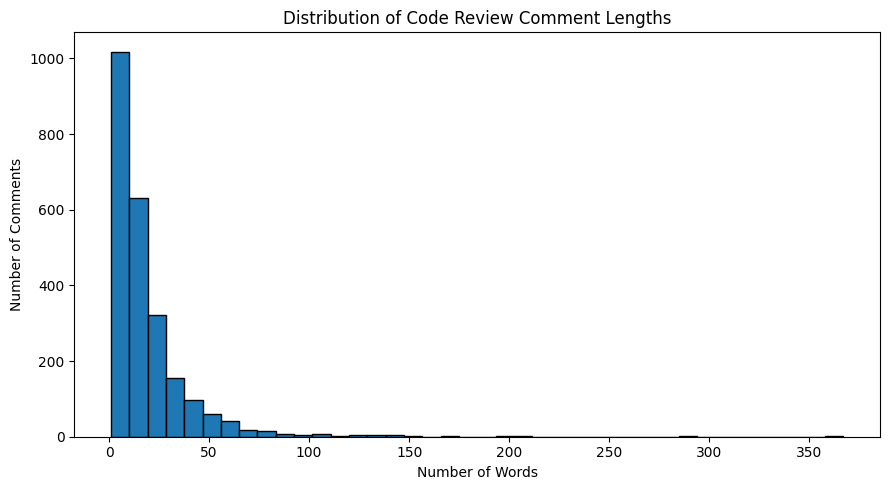

In [ ]:
if "bodyText" in df.columns:

    comment_text = df["bodyText"].fillna("").astype(str)

    df["comment_length_chars"] = comment_text.str.len()
    df["comment_length_words"] = comment_text.str.split().str.len()

    display(df[["comment_length_chars", "comment_length_words"]].describe())

    plt.figure(figsize=(9, 5))

    plt.hist(df["comment_length_words"],bins=40,edgecolor="black")

    plt.title("Distribution of Code Review Comment Lengths")
    plt.xlabel("Number of Words")
    plt.ylabel("Number of Comments")

    plt.tight_layout()
    plt.show()

Label Distribution:


RQ1 - Understandability?
No         1333
Yes        1012
Discard      56
Name: count, dtype: int64


Label Percentages:


RQ1 - Understandability?
No         55.52
Yes        42.15
Discard     2.33
Name: proportion, dtype: float64

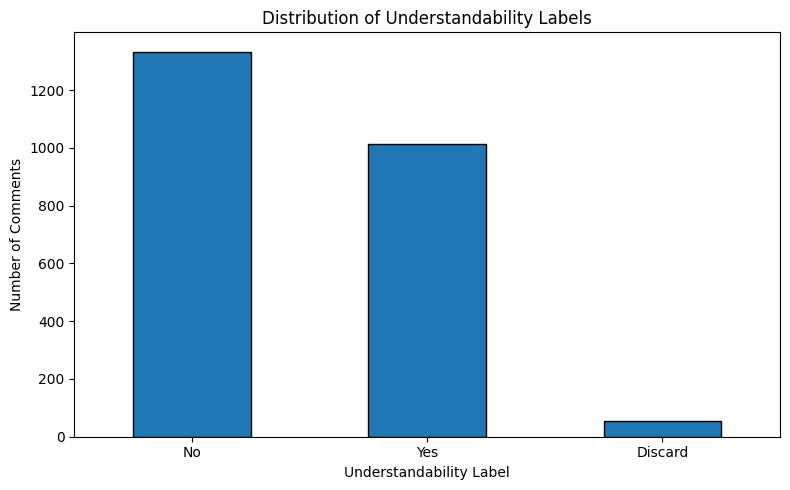

In [ ]:
label_column = "RQ1 - Understandability?"

# Count the number of instances for each label
label_counts = df[label_column].value_counts(dropna=False)

print("Label Distribution:")
display(label_counts)

# Calculate percentage distribution
label_percentages = (df[label_column].value_counts(normalize=True, dropna=False).mul(100).round(2))

print("\nLabel Percentages:")
display(label_percentages)

# Visualize distribution
plt.figure(figsize=(8, 5))

label_counts.plot( kind="bar",edgecolor="black")

plt.title("Distribution of Understandability Labels")
plt.xlabel("Understandability Label")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Identify all records that share the same comment text
duplicates = df[df.duplicated(subset=["bodyText"], keep=False)].copy()

# Sort duplicates for inspection
duplicates = duplicates.sort_values("bodyText")

print("Total records involved in duplicate groups:")
print(len(duplicates))

print("\nNumber of unique duplicated texts:")
print(duplicates["bodyText"].nunique())

display(duplicates[["project","pr_number","bodyText","RQ1 - Understandability?"]])

# Check whether identical texts have different labels
conflicting_labels = (duplicates.groupby("bodyText")[label_column].nunique())

print("\nDuplicate texts with conflicting labels:")
print((conflicting_labels > 1).sum())

Total records involved in duplicate groups:
45

Number of unique duplicated texts:
16


,project,pr_number,bodyText,RQ1 - Understandability?
2390,trinodb/trino,5936,#ERROR!,No
1913,google/ground-android,580,#ERROR!,No
1829,fabricmc/fabric,641,2020,No
1828,fabricmc/fabric,641,2020,No
2257,openmrs/openmrs-module-fhir2,115,Ditto,Discard
2256,openmrs/openmrs-module-fhir2,115,Ditto,Discard
2149,odpi/egeria,3707,Ditto,Discard
949,knowm/xchange,3539,Ditto,No
2338,senx/warp10-platform,751,Ditto.,Discard
208,apache/jena,792,Ditto.,Discard



Duplicate texts with conflicting labels:
3


Number of unique projects: 363

Comments per project:


count    363.000000
mean       6.614325
std        2.280112
min        1.000000
25%        5.000000
50%        7.000000
75%        8.000000
max       15.000000
Name: count, dtype: float64


Top 10 projects by comment count:


project
nuxeo/nuxeo                     15
fabricmc/fabric                 15
crate/crate                     14
palantir/gradle-baseline        12
velocitypowered/velocity        12
marklogic/marklogic-data-hub    12
b2ihealthcare/snow-owl          12
apache/ignite                   11
all-of-us/workbench             11
apache/parquet-mr               11
Name: count, dtype: int64

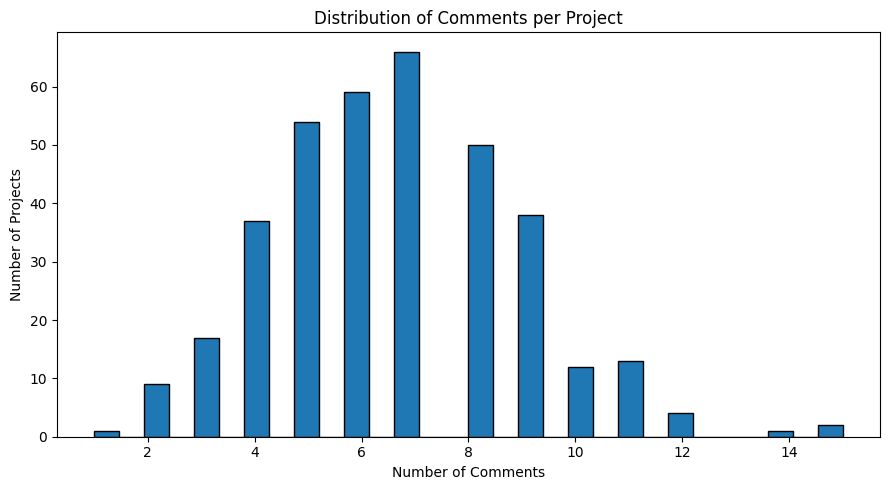

In [ ]:
# Number of distinct projects
num_projects = df["project"].nunique()

print("Number of unique projects:", num_projects)

# Number of comments per project
project_counts = df["project"].value_counts()

print("\nComments per project:")
display(project_counts.describe())

print("\nTop 10 projects by comment count:")
display(project_counts.head(10))

# Plot distribution
plt.figure(figsize=(9, 5))

plt.hist(project_counts,bins=30,edgecolor="black")

plt.title("Distribution of Comments per Project")
plt.xlabel("Number of Comments")
plt.ylabel("Number of Projects")

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
RQ1 - Understandability?,,,,,,,,
No,1333.0,21.375094,23.517077,1.0,8.0,14.0,26.0,291.0
Yes,1012.0,16.123518,19.908981,1.0,5.0,11.0,20.0,367.0


<Figure size 900x500 with 0 Axes>

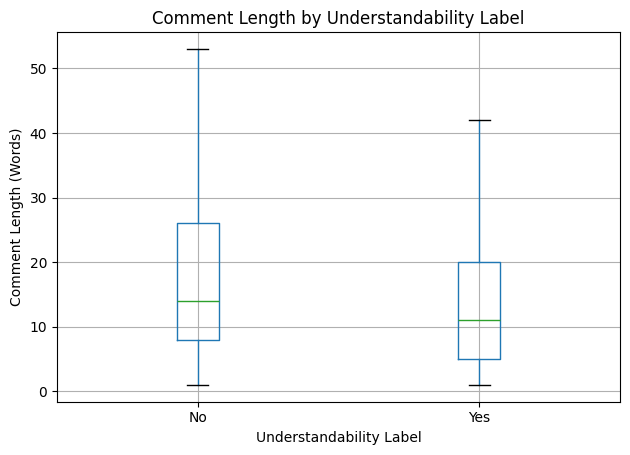

In [ ]:
# Retain only Yes and No for this analysis
binary_df = df[df[label_column].isin(["Yes", "No"])].copy()

# Summary statistics by class
length_summary = (binary_df.groupby(label_column)["comment_length_words"].describe())

display(length_summary)

# Visualize lengths by label
plt.figure(figsize=(9, 5))

binary_df.boxplot(column="comment_length_words",by=label_column,showfliers=False)

plt.title("Comment Length by Understandability Label")
plt.suptitle("")
plt.xlabel("Understandability Label")
plt.ylabel("Comment Length (Words)")

plt.tight_layout()
plt.show()

In [ ]:
# Create an exploratory subset without changing the original dataframe
binary_df = df[df["RQ1 - Understandability?"].isin(["Yes", "No"])].copy()

# Identify repeated texts in the binary dataset
binary_duplicates = binary_df[binary_df.duplicated(subset=["bodyText"], keep=False)].copy()

# Count distinct labels per repeated text
label_variations = (binary_duplicates.groupby("bodyText")["RQ1 - Understandability?"].nunique())

print("Binary classification records:", len(binary_df))
print("Records in duplicate groups:", len(binary_duplicates))
print("Unique repeated texts:", binary_duplicates["bodyText"].nunique())
print("Repeated texts with conflicting Yes/No labels:",(label_variations > 1).sum())

display(binary_duplicates[["project", "pr_number", "bodyText", "RQ1 - Understandability?"]].sort_values("bodyText"))

Binary classification records: 2345
Records in duplicate groups: 28
Unique repeated texts: 11
Repeated texts with conflicting Yes/No labels: 0


,project,pr_number,bodyText,RQ1 - Understandability?
2390,trinodb/trino,5936,#ERROR!,No
1913,google/ground-android,580,#ERROR!,No
1829,fabricmc/fabric,641,2020,No
1828,fabricmc/fabric,641,2020,No
1046,micronaut-projects/micronaut-core,4717,Missing javadoc,Yes
613,eclipse/che-che4z-lsp-for-cobol,580,Missing javadoc,Yes
2252,openmrs/openmrs-core,3360,Suggested change,Yes
1033,megamek/megamek,2334,Suggested change,Yes
888,kiegroup/appformer,956,Suggested change,Yes
1038,megamek/mekhq,2144,Suggested change * a...,Yes


In [ ]:
from transformers import AutoTokenizer

model_name = "sentence-transformers/all-mpnet-base-v2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

texts = binary_df["bodyText"].tolist()

token_lengths = [len(tokenizer.encode(text, add_special_tokens=True)) for text in texts]

max_tokens = 384

print("Maximum tokenizer length:", max(token_lengths))
print("Median tokenizer length:", np.median(token_lengths))

print("Comments exceeding 384 tokens:", sum(length > max_tokens for length in token_lengths))

print("Percentage exceeding 384 tokens:", round(sum(length > max_tokens for length in token_lengths) / len(token_lengths) * 100, 2))

d:\uOttawa\Fall_26\CSI5187\project\nlp_ml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\uOttawa\Fall_26\CSI5187\project\nlp_ml\lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\bhair\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administra

Maximum tokenizer length: 1120
Median tokenizer length: 23.0
Comments exceeding 384 tokens: 5
Percentage exceeding 384 tokens: 0.21


## Exploratory Data Analysis — Summary

### 1. Dataset Overview
The CODE-UP dataset contains **2,401 code-review comments from 363 software projects**, with 24 columns containing review information and annotations.

For our binary classification task:
- **Input (`bodyText`):** The actual code-review comment.
- **Target (`RQ1 - Understandability?`):** Indicates whether the comment concerns code understandability.
- **Project (`project`):** Identifies the software project from which the comment originated.

### 2. Class Distribution
The dataset contains:
- **No:** 1,333 comments (55.52%)
- **Yes:** 1,012 comments (42.15%)
- **Discard:** 56 comments (2.33%)

After excluding `Discard`, **2,345 comments remain**, consisting of 56.84% `No` and 43.16% `Yes`.

The classes are moderately imbalanced. Therefore, we will use `class_weight='balanced'` in Logistic Regression and emphasize **macro-F1** during evaluation to give both classes equal importance.

### 3. Data Quality and Duplicates
No missing or empty values were found in `bodyText` or the classification labels.

After excluding `Discard`, **28 records belong to 11 groups of identical comment texts**, with no conflicting `Yes`/`No` labels.

We will initially retain these records to preserve the original dataset. However, identical comments appearing in both training and testing could artificially improve classification performance. We will check for this during data splitting.

### 4. Comment-Length Analysis
The comment-length distribution is **right-skewed**, meaning most comments are short, while a small number are considerably longer.

- Overall median: **13 words**
- Overall mean: **18.79 words**
- Maximum: **367 words**

Understandability-related comments (`Yes`) have a median length of **11 words**, compared with **14 words** for unrelated comments (`No`).

This suggests that understandability suggestions are generally shorter, although comment length alone cannot reliably distinguish the two classes.

### 5. Project Distribution
The 363 projects contain between **1 and 15 comments each**, averaging approximately 6.61 comments per project.

With a stratified random split, comments from the same project may appear in both training and testing. Consequently, the evaluation may not fully represent performance on entirely unseen software projects.

We will retain the proposed **70/15/15 stratified split** and acknowledge this limitation.

### 6. Sentence Transformer Token Analysis
Using the `all-mpnet-base-v2` tokenizer:

- Median sequence length: **23 tokens**
- Maximum sequence length: **1,120 tokens**
- Comments exceeding 384 tokens: **5 (0.21%)**

Most comments fall within the Sentence Transformer's expected input limit. The five longer comments will be retained, with truncation applied during embedding generation using the model's configured maximum sequence length.

### 7. Conclusion and Next Steps
The exploratory analysis confirms that the dataset is suitable for the proposed NLP and ML classification task.

Based on these findings, we will:

1. **Preprocess the dataset:** Remove `Discard`, encode `Yes` as `1` and `No` as `0`, and preserve the original comment text without aggressive normalization.
2. **Split the dataset:** Create reproducible stratified training (70%), validation (15%), and testing (15%) partitions, while checking duplicate-text overlap.
3. **Implement both approaches:** Train TF-IDF + Logistic Regression and Sentence Transformer + Logistic Regression using identical data partitions.
4. **Evaluate and compare:** Use accuracy, precision, recall, macro-F1, confusion matrices, and error analysis to determine whether semantic representations outperform lexical representations.

The goal is to ensure a **fair, reproducible comparison** in which the primary difference between the two approaches is how code-review comments are represented numerically.